In [1]:
import numpy as np
import cv2
import glob
import matplotlib.pyplot as plt
import open3d as o3d
import copy

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
img = cv2.imread("0_calib/left/000.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
h, w = img.shape[:2]
image_size = (w, h)
print((w,h))

(1280, 720)


In [ ]:
nb_vertical = 5
nb_horizontal = 7
space_between_checkers = 25 # mm

image_range = 37

def get_calib_filename(idx: int):
    return f"0_calib/left/{idx:03d}.png", f"0_calib/right/{idx:03d}.png"

# Prepare object points, like (0, 0, 0), (1, 0, 0), (2, 0, 0) ....,(6, 5, 0).
objp = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)
objp[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

# Arrays to store object points and image points from all the images.
objpoints = []  # 3D point in real world space.
imgpoints_left = []  # 2D points in image plane.
imgpoints_right = []  # 2D points in image plane.

skip_images = [4,6,7,14,17]

for image_idx in range(image_range):

    if image_idx in skip_images:
        continue

    fname_left, fname_right = get_calib_filename(image_idx)

    img_left = cv2.imread(fname_left)
    img_right = cv2.imread(fname_right)

    # corners_left (N, 1, 2) pixel coordinates for every corner of the chessboard
    ret_left, corners_left = cv2.findChessboardCornersSB(
        img_left, (nb_vertical, nb_horizontal), None
    )

    ret_right, corners_right = cv2.findChessboardCornersSB(
        img_right, (nb_vertical, nb_horizontal), None
    )

    # If found, add object points, image points (after refining them).
    if not (ret_left and ret_right):
        continue

    objpoints.append(objp.copy())
    imgpoints_left.append(corners_left)
    imgpoints_right.append(corners_right)

    # # Draw and display the corners.
    # img_drawn = cv2.drawChessboardCorners(
    #     img_left, (nb_vertical, nb_horizontal), corners_left, ret_left
    # )

    # img_drawn = cv2.drawChessboardCorners(
    #     img_drawn, (nb_vertical, nb_horizontal), corners_right, ret_right
    # )

    # plt.title(f"Index: {image_idx}")
    # plt.imshow(img_drawn)
    # plt.show()

    # cv2.imshow("img", img_drawn)
    # cv2.waitKey(500)

# cv2.destroyAllWindows()


## K - Camera intrinsic matrix:
[[f_x     0       c_x ],
 [0       f_y     c_y ],
 [0       0       1   ]]
f_x: Focal length in horizontal pixel units
f_y: Focal length in vertical pixel units
c_x: Horizontal coordinate of the principal point
c_y: Vertical coordinate of the principal point

## dist - Lens distortion:
dist = [k_1, k_2, p_1, p_2, k_3]

k_1, k_2, k_3: Radial distortion

p_1, p_2: Tangential distortion

## rvecs - Rotation Vectors
rvecs: contains the rotation of the chessboard relative to the camera for each calibration image.

r = [r_x, r_y, r_z].T

Good function to know; convert rotation vector to matrix form:
```
R, _ = cv2.Rodrigues(rvecs[0])
```

## tvecs - Translation vectors
tvecs: contains the translation of the chessboard coordinate system relative to the camera for every calibration image.

t = [t_x, t_y, t_z].T

Total transformation of a point:
```
P_camera = R * P_chessboard + t
```
Where `P_cs` is the point "P" in coordinate system "cs".



In [58]:
rms_left, K_left, dist_left, rvecs_left, tvecs_left = cv2.calibrateCamera(
    objpoints, imgpoints_left, image_size, None, None
)

rms_right, K_right, dist_right, rvecs_right, tvecs_right = cv2.calibrateCamera(
    objpoints, imgpoints_right, image_size, None, None
)

R Matrix: Rotation matrix from left to right.
T vector: Translation vector from the left to right.

$$
P_{right} = R * P_{left} + T
$$

The baseline:

$$
B = \|{T}\| = \sqrt{T_x^2 + T_y^2 + T_z^2}
$$

In [59]:
rms_stereo, K_left, dist_left, K_right, dist_right, R, T, E, F = cv2.stereoCalibrate(
    objpoints,
    imgpoints_left, imgpoints_right,
    K_left, dist_left,
    K_right, dist_right,
    image_size,
    flags=cv2.CALIB_FIX_INTRINSIC
)

In [60]:
print(rms_left, rms_right, rms_stereo)

0.14618808369801153 0.14174906509196147 0.2820292899912919


In [61]:
R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(
    K_left, dist_left,
    K_right, dist_right,
    image_size,
    R, T,
    flags=cv2.CALIB_ZERO_DISPARITY,
    alpha=0
)
print(roi1)
print(roi2)

(0, 0, 1280, 720)
(0, 0, 1280, 720)


In [62]:
mapLx, mapLy = cv2.initUndistortRectifyMap(K_left, dist_left, R1, P1, (w,h), cv2.CV_32FC1)
mapRx, mapRy = cv2.initUndistortRectifyMap(K_right, dist_right, R2, P2, (w,h), cv2.CV_32FC1)

In [63]:
np.savez_compressed("calibration_maps.npz",
    mapLx=mapLx,
    mapLy=mapLy,
    mapRx=mapRx,
    mapRy=mapRy,
)

In [64]:
def generateRemapFunction(map_x, map_y):
    def fn(img):
        return cv2.remap(
            img,
            map_x, map_y,
            cv2.INTER_LINEAR
        )

    return fn

def loadVariables(filename: str):
    calibration_maps = globals().update(np.load(filename, allow_pickle=True))

In [65]:
loadVariables("calibration_maps.npz")

RemapL = generateRemapFunction(mapLx, mapLy)
RemapR = generateRemapFunction(mapRx, mapRy)

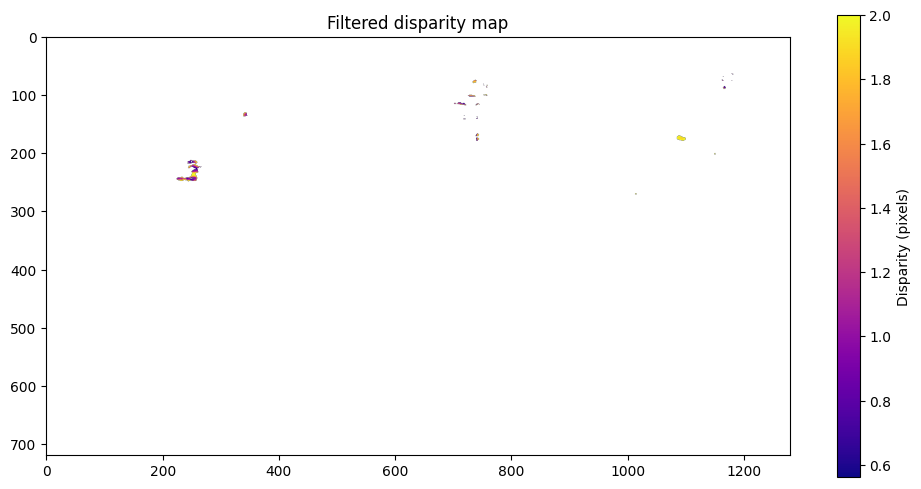

In [ ]:
# STEP 1 - Create 3D point cloud.
def get_no_obstacle_filename(idx: int):
    return f"1_no_obstacle/left/{idx:06d}.png", f"1_no_obstacle/right/{idx:06d}.png"

block_size = 3
min_disp = 0
num_disp = 5*16  # must be divisible by 16

left_matcher = cv2.StereoSGBM_create(
    minDisparity=min_disp,
    # Start searching at disparity 0, so far points can still match.
    numDisparities=num_disp,
    blockSize=block_size,
    P1=8*block_size**2,
    P2=32*block_size**2,
    disp12MaxDiff=1,
    # Drop a pixel when the left-right and right-left disparities differ by more than 1.
    preFilterCap=31,
    # Clip the image gradient so bright spots do not dominate the match cost.
    uniquenessRatio=20,
    # Keep a match only when it beats the second-best cost by xx percent.
    speckleWindowSize=80,
    # Remove connected disparity blobs smaller than 80 pixels.
    speckleRange=2,
    # Pixels in one blob may differ by at most 2 disparity levels.
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    # Match along horizontal, vertical, and diagonal paths.
)
right_matcher = cv2.ximgproc.createRightMatcher(left_matcher)
wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
wls.setLambda(2000)
wls.setSigmaColor(0.8)

n_img = 1

disps = np.zeros((n_img, h, w))
points_3d = []

left_filename, right_filename = get_no_obstacle_filename(0)

img_left = cv2.imread(left_filename)
img_right = cv2.imread(right_filename)

img_rect_left = cv2.remap(img_left, mapLx, mapLy, cv2.INTER_LINEAR)
img_rect_right = cv2.remap(img_right, mapRx, mapRy, cv2.INTER_LINEAR)

gray_left = cv2.cvtColor(img_rect_left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(img_rect_right, cv2.COLOR_BGR2GRAY)

disp_left = left_matcher.compute(gray_left, gray_right).astype(np.float32) / 16.0
disp_right = left_matcher.compute(gray_right, gray_left).astype(np.float32) / 16.0

# Spread reliable disparity into flat pixels, but stop at a color edge
disparity_map = wls.filter(disp_left, img_left, None, disp_right).astype(np.float32) / 16

disparity_map[disparity_map < 0] = np.nan

# raw_disparity = disp_left.astype(np.float32) / 16.0
# filtered_disparity = (
#     wls.filter(disp_left, gray_left, None, disp_right)
#     .astype(np.float32) / 16.0
# )
# confidence = wls.getConfidenceMap()

point_3d = cv2.reprojectImageTo3D(disp, Q)

depth = point_3d[:,:,2]

valid = (
    (disp > min_disp) & 
    np.isfinite(point_3d).all(axis=2) &
    (depth > 500) &
    (depth < 5000)
)

disp_vis = np.ma.masked_where(~valid, disp)

plt.figure(figsize=(12, 6))
plt.imshow(disp_vis, cmap="plasma")
plt.colorbar(label="Disparity (pixels)")
plt.title("Filtered disparity map")
plt.show()

points = point_3d[valid]

rgb_left = cv2.cvtColor(img_rect_left, cv2.COLOR_BGR2RGB)
colors = rgb_left[valid].astype(np.float64) / 255.0

points = points.astype(np.float64) / 1000.0

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

o3d.visualization.draw_geometries([ pcd ])

# points_3d.append(point_3d)



In [70]:
print("Q matrix:")
print(Q)

print("Stereo translation:")
print(T)

print("Projection matrices:")
print(P1)
print(P2)

Q matrix:
[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00 -6.15640686e+02]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00 -3.92114346e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  6.64795209e+02]
 [ 0.00000000e+00  0.00000000e+00  6.61181152e-01 -0.00000000e+00]]
Stereo translation:
[[-1.51160574]
 [-0.00386705]
 [-0.05022373]]
Projection matrices:
[[664.79520937   0.         615.64068604   0.        ]
 [  0.         664.79520937 392.11434555   0.        ]
 [  0.           0.           1.           0.        ]]
[[ 6.64795209e+02  0.00000000e+00  6.15640686e+02 -1.00546606e+03]
 [ 0.00000000e+00  6.64795209e+02  3.92114346e+02  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]]


In [68]:
def draw_registrations(source, transformation=None, recolor=False):
    source_temp = copy.deepcopy(source)
    if recolor:
        source_temp.paint_uniform_color([1, 0.706, 0])
    if transformation is not None:
        source_temp.transform(transformation)
    o3d.visualization.draw_geometries([source_temp])

# draw_registrations(points_3d)

In [69]:
# Following the RGB-D to point-cloud conversion shown above, this helper loads
# any frame by its ID and returns the corresponding Open3D point cloud.
# This avoids repeating the same loading and reprojection code throughout
# the rest of the exercises.
def load_pcd(frame_id, camera):
    """
    Load one RGB-D frame and convert it into an Open3D point cloud.
    """
    # Read raw data of frame
    color_raw = o3d.io.read_image(f"car_challenge/rgb/{frame_id+1:07d}.jpg")
    depth_raw = o3d.io.read_image(f"car_challenge/depth/{frame_id+1:07d}.png")
    
    # Get RGBD
    rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth(
        color_raw, depth_raw, convert_rgb_to_intensity=True
    )
    
    # Get point cloud
    pcd = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd_image, camera)
    pcd.transform([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, 1]])
    return pcd